<a href="https://colab.research.google.com/github/butthamza20/ECS708U-P-Fashion-MNIST-Coursework/blob/main/ECS708U_P_Fashion_MNIST_Coursework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0.1 Fixed data partitions

### Importing libraries

In [ ]:
import torch
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import random
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
from torch.utils.data import DataLoader

### Loading the Fashion MNIST training dataset

In [ ]:
train_data = datasets.FashionMNIST(root='data', train=True, download=True, transform=transforms.ToTensor())

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 209kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.91MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.51MB/s]


### Testing the training dataset

In [ ]:
train_data_length = len(train_data)

In [ ]:
random_num = random.randint(0, train_data_length)
train_data_image_1, train_data_label_1 = train_data[random_num]

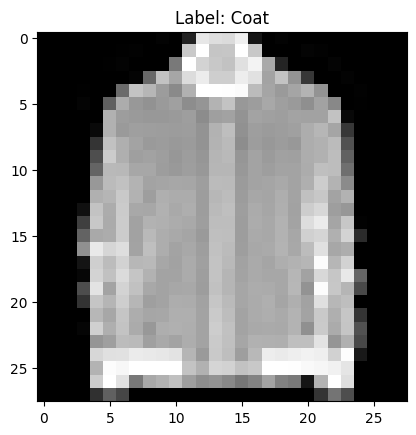

In [ ]:
plt.imshow(train_data_image_1.squeeze(), cmap='gray', interpolation='nearest')
plt.title(f"Label: {train_data.classes[train_data_label_1]}")
plt.show()

In [ ]:
random_num = random.randint(0, train_data_length)
train_data_image_2, train_data_label_2 = train_data[random_num]

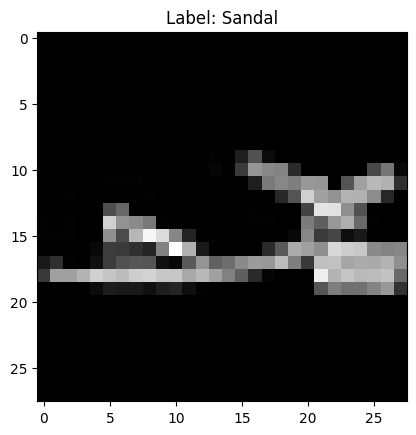

In [ ]:
plt.imshow(train_data_image_2.squeeze(), cmap='gray', interpolation='nearest')
plt.title(f"Label: {train_data.classes[train_data_label_2]}")
plt.show()

In [ ]:
random_num = random.randint(0, train_data_length)
train_data_image_3, train_data_label_3 = train_data[random_num]

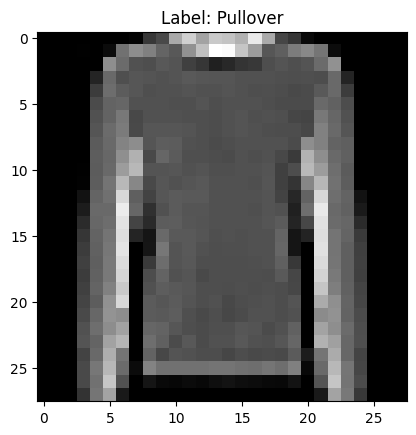

In [ ]:
plt.imshow(train_data_image_3.squeeze(), cmap='gray', interpolation='nearest')
plt.title(f"Label: {train_data.classes[train_data_label_3]}")
plt.show()

### Validating the training dataset

In [ ]:
all_indices = list(range(train_data_length))
all_labels = train_data.targets

In [ ]:
split_seed = 42
train_indices, val_indices = train_test_split(all_indices, test_size = 10000, stratify = all_labels,
    random_state = split_seed)

In [ ]:
train_set = Subset(train_data, train_indices)
val_set = Subset(train_data, val_indices)

In [ ]:
print("Train size:", len(train_set))
print("Validation size:", len(val_set))

Train size: 50000
Validation size: 10000


In [ ]:
overlap = set(train_indices) & set(val_indices)
print("Images in both sets:", len(overlap))

Images in both sets: 0


In [ ]:
print("Train class counts:", torch.bincount(all_labels[train_indices]))
print("Validation class counts:", torch.bincount(all_labels[val_indices]))

Train class counts: tensor([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000])
Validation class counts: tensor([1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000])


In [ ]:
size_of_batch = 64
g = torch.Generator()
g.manual_seed(42)

In [ ]:
train_loader = DataLoader(train_set, batch_size = size_of_batch, shuffle = True, generator = g)

In [ ]:
val_loader = DataLoader(val_set, batch_size = size_of_batch, shuffle = False)

In [ ]:
temp_images, temp_labels = next(iter(train_loader))

In [ ]:
print(temp_images.shape)
print(temp_labels.shape)
print(len(train_loader))

torch.Size([64, 1, 28, 28])
torch.Size([64])
782


In [ ]:
print(len(val_loader))

157
